# Validating the SPH ECG-FM embeddings and auditing for data leakage

**Why:** embeddings + age/sex reached AUPRC ~0.99 for AF at 2.6% prevalence. That is high enough to deserve scrutiny.
This notebook runs three independent tests. It needs **no GPU and no raw signals**, only the merged embeddings file
(`sph_ecgfm_all.npz` on Drive) and the small public label files (downloaded automatically).

| Test | Question it answers |
|---|---|
| **1. Integrity and alignment** | Are the embeddings finite, non-degenerate, and attached to the *right* records? |
| **2. Split / leakage audit** | Could the train and test folds share patients, near-duplicate ECGs, or an ID-order shortcut? |
| **3. Controls** | Does the score behave like real signal? (shuffled labels, AF vs other abnormal ECGs, age and sex as positive controls) |

Each check is logged as `PASS`, `CHECK` (look into it) or `INFO`. The thresholds are **rule-of-thumb heuristics we chose**,
not published cutoffs, so read the numbers and not just the labels. Expected runtime: roughly 15-30 minutes on a CPU runtime
(set `N_PERM` lower to speed up).

In [1]:
import os, re, glob, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, roc_auc_score
warnings.filterwarnings("ignore")

SEED = 0
N_PERM = 5                                    # shuffled-label repeats (each is one 5-fold CV fit)
OUT_DIR = "/content/drive/MyDrive/sph_ecgfm"  # where sph_ecgfm_all.npz lives
DATA_DIR = "/content/sph_meta"                # small label files are downloaded here
FS, WIN = 500, 2500
os.makedirs(DATA_DIR, exist_ok=True)

summary = []
def log(test, check, value, status):
    summary.append({"Test": test, "Check": check, "Value": value, "Status": status})
    print(f"[{status:5s}] {check}: {value}")

In [2]:
# Mount Google Drive (skipped automatically outside Colab)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

Mounted at /content/drive


## Load the embeddings and the labels

In [3]:
# ---- embeddings -------------------------------------------------------------
EMB_PATH = os.path.join(OUT_DIR, "sph_ecgfm_all.npz")
if os.path.exists(EMB_PATH):
    z = dict(np.load(EMB_PATH, allow_pickle=True))
else:                                           # fallback: merge the chunk files
    files = sorted(glob.glob(os.path.join(OUT_DIR, "chunk_*.npz")),
                   key=lambda p: int(re.search(r"chunk_(\d+)_", p).group(1)))
    assert files, f"No embeddings found in {OUT_DIR}"
    parts = [np.load(f, allow_pickle=True) for f in files]
    z = {k: np.concatenate([p[k] for p in parts]) for k in ["ids", "emb", "nwin", "flat"]}
ids_all = np.array([str(i) for i in z["ids"]])
E_all = z["emb"].astype(np.float32)
nwin_stored = z["nwin"] if "nwin" in z else None
print("embeddings:", E_all.shape)

# ---- public label files -----------------------------------------------------
URLS = {"metadata.csv": "https://ndownloader.figshare.com/files/34793152",
        "code.csv":     "https://ndownloader.figshare.com/files/32630954"}
for name, url in URLS.items():
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as r, open(path, "wb") as f:
            f.write(r.read())
meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
code = pd.read_csv(os.path.join(DATA_DIR, "code.csv")).astype(str)
meta["rec"] = meta["ECG_ID"].astype(str).str.replace(".h5", "", regex=False)
assert meta["rec"].is_unique, "Duplicate ECG_IDs in metadata"

# ---- find the AF / flutter / normal codes by description --------------------
def find_code(pattern, exclude=None, fullmatch=False):
    d = code["Description"]
    m = d.str.fullmatch(pattern, case=False) if fullmatch else d.str.contains(pattern, case=False, regex=True)
    if exclude:
        m &= ~d.str.contains(exclude, case=False, regex=True)
    return code[m]

def resolve(found, label):
    if len(found) != 1:
        print(found.to_string())
        raise ValueError(f"Could not uniquely identify the {label} code - set it by hand.")
    return found["Code"].iloc[0]

AF_CODE      = resolve(find_code(r"atrial fibrillation", exclude="ventricular"), "AF")
FLUTTER_CODE = resolve(find_code(r"atrial flutter",      exclude="ventricular"), "flutter")
NORMAL_CODE  = resolve(find_code(r"\s*normal ecg\s*", fullmatch=True),        "normal")
print("codes -> AF:", AF_CODE, "| flutter:", FLUTTER_CODE, "| normal:", NORMAL_CODE)

def primary_codes(s):
    return {c.split("+")[0].strip() for c in str(s).split(";") if c.strip()}
meta["codes"] = meta["AHA_Code"].apply(primary_codes)
meta["af"] = meta["codes"].apply(lambda s: AF_CODE in s).astype(int)
meta["flutter_only"] = meta["codes"].apply(lambda s: FLUTTER_CODE in s) & (meta["af"] == 0)
meta["normal"] = meta["codes"].apply(lambda s: NORMAL_CODE in s)
meta["male"] = meta["Sex"].astype(str).str.lower().str.startswith("m").astype(int)

M = meta.set_index("rec").reindex(ids_all)       # metadata in the SAME ORDER as the embeddings

embeddings: (25770, 768)
codes -> AF: 50 | flutter: 51 | normal: 1


---
# Test 1 - Integrity and alignment

**What it does.** Checks the embedding file itself, without training anything.

* **Completeness and uniqueness:** every metadata record has exactly one embedding, with no NaN/Inf, no zero vectors, and no
  duplicated rows.
* **Window-count consistency:** during extraction we stored how many 5-s windows each record produced. That count must equal
  `floor(N / 2500)`, where `N` is the signal length listed in the *metadata*. If embeddings were attached to the wrong records,
  these would disagree for many records. This is the strongest alignment check available without the raw signals.
* **Not collapsed:** the embeddings should spread over many dimensions (PCA), not sit on a few.
* **Same-patient similarity:** two ECGs from the same patient should be more alike than two random ECGs. If IDs and embeddings
  were scrambled, same-patient pairs would look like random pairs. (Embeddings are mean-centred first, because pooled
  transformer outputs share a large common component that inflates every cosine similarity.)

**Why it matters for leakage.** A misaligned file would give meaningless or, worse, accidentally label-linked results.

[PASS ] Embedding rows vs metadata rows: 25770 vs 25770
[PASS ] Record IDs unique in embeddings file: True
[PASS ] Embedding IDs not found in metadata: 0
[PASS ] Metadata IDs with no embedding: 0
[PASS ] Rows containing NaN/Inf: 0
[PASS ] Zero-norm embeddings: 0
[CHECK] Exactly duplicated embedding rows: 111
[INFO ] Constant (dead) dimensions: 0
[PASS ] Records whose stored window count != floor(N/2500) from metadata: 0
[PASS ] PCA components needed for 90% variance: 45
[PASS ] Same-patient pairs (1066): mean cosine 0.720 vs random 0.000; AUROC: 0.978


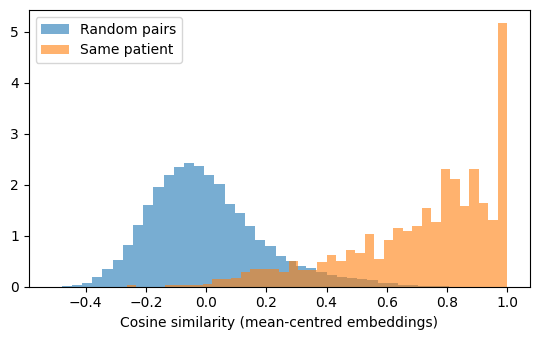

In [4]:
n_meta = len(meta)
log("1", "Embedding rows vs metadata rows", f"{len(ids_all)} vs {n_meta}", "PASS" if len(ids_all) == n_meta else "CHECK")
log("1", "Record IDs unique in embeddings file", bool(pd.Series(ids_all).is_unique), "PASS" if pd.Series(ids_all).is_unique else "CHECK")
missing = int(M["Patient_ID"].isna().sum())
log("1", "Embedding IDs not found in metadata", missing, "PASS" if missing == 0 else "CHECK")
log("1", "Metadata IDs with no embedding", int((~meta["rec"].isin(ids_all)).sum()),
    "PASS" if meta["rec"].isin(ids_all).all() else "CHECK")
assert missing == 0, "Some embedding IDs are not in metadata - fix the ID format before continuing."

bad = int((~np.isfinite(E_all)).any(axis=1).sum())
log("1", "Rows containing NaN/Inf", bad, "PASS" if bad == 0 else "CHECK")
norms = np.linalg.norm(E_all, axis=1)
log("1", "Zero-norm embeddings", int((norms < 1e-8).sum()), "PASS" if (norms < 1e-8).sum() == 0 else "CHECK")
dup_rows = int(pd.DataFrame(np.round(E_all, 4)).duplicated().sum())
log("1", "Exactly duplicated embedding rows", dup_rows, "PASS" if dup_rows == 0 else "CHECK")
log("1", "Constant (dead) dimensions", int((E_all.std(0) < 1e-6).sum()), "INFO")

# window counts: stored during extraction vs implied by metadata signal length
if nwin_stored is not None:
    expected = (M["N"].astype(int).values // WIN)
    mism = int((nwin_stored.astype(int) != expected).sum())
    log("1", "Records whose stored window count != floor(N/2500) from metadata", mism, "PASS" if mism == 0 else "CHECK")
else:
    log("1", "Window-count check", "skipped (no nwin array in file)", "INFO")

# not collapsed
n90 = PCA(n_components=0.9, svd_solver="full").fit(E_all).n_components_
log("1", "PCA components needed for 90% variance", int(n90), "PASS" if n90 >= 3 else "CHECK")

# same-patient vs random-pair similarity (mean-centred cosine)
Ec = E_all - E_all.mean(0)
Ec = Ec / (np.linalg.norm(Ec, axis=1, keepdims=True) + 1e-12)
grp = pd.Series(np.arange(len(M))).groupby(M["Patient_ID"].values).apply(list)
pairs = [v[:2] for v in grp if len(v) >= 2]
same = np.array([Ec[a] @ Ec[b] for a, b in pairs])
rng = np.random.default_rng(SEED)
ij = rng.integers(0, len(Ec), (len(pairs) * 20, 2)); ij = ij[ij[:, 0] != ij[:, 1]]
rand = np.einsum("ij,ij->i", Ec[ij[:, 0]], Ec[ij[:, 1]])
auc_pair = roc_auc_score(np.r_[np.ones(len(same)), np.zeros(len(rand))], np.r_[same, rand])
log("1", f"Same-patient pairs ({len(pairs)}): mean cosine {same.mean():.3f} vs random {rand.mean():.3f}; AUROC", round(auc_pair, 3),
    "PASS" if (auc_pair > 0.6 and len(pairs) >= 30) else ("INFO" if len(pairs) < 30 else "CHECK"))

plt.figure(figsize=(5.5, 3.5))
plt.hist(rand, bins=40, alpha=.6, density=True, label="Random pairs")
plt.hist(same, bins=40, alpha=.6, density=True, label="Same patient")
plt.xlabel("Cosine similarity (mean-centred embeddings)"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "validation_fig_same_patient.png"), dpi=200); plt.show()

---
# Test 2 - Split / leakage audit

**What it does.** Rebuilds the exact cross-validation used for the AF result (5-fold, stratified, **grouped by patient**)
and asks whether information could have crossed from training to test:

* **Patient overlap:** no `Patient_ID` may appear in both a training and a test fold.
* **Near-duplicate ECGs across folds:** for every test record, find its most similar *training* record (mean-centred cosine).
  Identical ECGs filed under different patient IDs would show up as near-1.0 similarities. We report the distribution, count
  records above 0.99 (a heuristic cutoff), and check whether those near-duplicates share the test record's AF label.
* **Grouped vs naive splitting:** score the same model with patient-grouped folds and with ordinary record-level folds. If
  patient overlap were inflating the result, the naive score would be clearly higher.
* **Record-order shortcut:** if AF rate trends with the numeric `ECG_ID` (a proxy for filing order), an ID-correlated artifact
  could be exploitable. A near-0.5 AUROC for the ID number alone means no such trend.

**Why it matters.** These are the three most common ways an AUPRC of ~0.99 turns out to be fake.

In [5]:
# ---- analysis cohort: drop flutter-only records (same as the main analysis) ----
keep = np.where(~M["flutter_only"].values)[0]
D = M.iloc[keep]
E, Ecd = E_all[keep], Ec[keep]
y = D["af"].values.astype(int)
groups = D["Patient_ID"].values
X = np.hstack([E, D[["Age", "male"]].values.astype(float)])     # embeddings + age + sex (the model being scrutinised)
print(f"cohort: {len(D):,} records | AF {y.sum()} | prevalence {y.mean():.4f}")

folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, groups))

def oof(Xm, target, folds_, C=0.1):
    p = np.zeros(len(target))
    for tr, te in folds_:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, class_weight="balanced"))
        m.fit(Xm[tr], target[tr]); p[te] = m.predict_proba(Xm[te])[:, 1]
    return p

# 2a. patient overlap
overlap = sum(len(set(groups[tr]) & set(groups[te])) for tr, te in folds)
log("2", "Patients appearing in both train and test folds", overlap, "PASS" if overlap == 0 else "CHECK")
print("AF per test fold:", [int(y[te].sum()) for _, te in folds])

cohort: 25,671 records | AF 675 | prevalence 0.0263
[PASS ] Patients appearing in both train and test folds: 0
AF per test fold: [143, 136, 124, 130, 142]


In [6]:
# 2b. near-duplicates between each test record and the training records of its fold
maxsim = np.zeros(len(E)); nn = np.zeros(len(E), dtype=int)
for tr, te in folds:
    Tr = Ecd[tr]
    for s in range(0, len(te), 2000):
        idx = te[s:s + 2000]
        S = Ecd[idx] @ Tr.T
        j = S.argmax(1)
        maxsim[idx] = S[np.arange(len(idx)), j]; nn[idx] = tr[j]
print("nearest-training-neighbour cosine, percentiles 50/90/99/99.9/100:",
      np.percentile(maxsim, [50, 90, 99, 99.9, 100]).round(4))
print("(for context, median same-patient similarity:", round(float(np.median(same)), 3), ")")
dupmask = maxsim >= 0.99
n_dup = int(dupmask.sum())
agree = float((y[nn[dupmask]] == y[dupmask]).mean()) if n_dup else float("nan")
log("2", "Test records with a >=0.99 near-duplicate in training (label agreement)",
    f"{n_dup} ({agree:.2f})" if n_dup else "0", "PASS" if n_dup <= 0.005 * len(E) else "CHECK")

# 2c. grouped vs naive folds
p_grouped = oof(X, y, folds)
naive_folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y))
p_naive = oof(X, y, naive_folds)
ap_g, ap_n = average_precision_score(y, p_grouped), average_precision_score(y, p_naive)
log("2", "AUPRC with patient-grouped folds", round(ap_g, 4), "INFO")
log("2", "AUPRC with naive record-level folds (gap vs grouped)", f"{ap_n:.4f} ({ap_n - ap_g:+.4f})",
    "PASS" if (ap_n - ap_g) < 0.01 else "CHECK")

# 2d. record-order shortcut
idnum = pd.to_numeric(D.index.to_series().str.extract(r"(\d+)")[0], errors="coerce").values
ok = ~np.isnan(idnum)
auc_id = roc_auc_score(y[ok], idnum[ok])
dec = pd.qcut(pd.Series(idnum[ok]), 10, labels=False, duplicates="drop")
print("AF rate by ECG_ID decile:", pd.Series(y[ok]).groupby(dec.values).mean().round(4).to_dict())
log("2", "AUROC of numeric ECG_ID alone for AF", round(auc_id, 3), "PASS" if 0.45 <= auc_id <= 0.55 else "CHECK")

nearest-training-neighbour cosine, percentiles 50/90/99/99.9/100: [0.8374 0.8957 0.9346 0.9552 0.9941]
(for context, median same-patient similarity: 0.785 )
[PASS ] Test records with a >=0.99 near-duplicate in training (label agreement): 2 (1.00)
[INFO ] AUPRC with patient-grouped folds: 0.9881
[PASS ] AUPRC with naive record-level folds (gap vs grouped): 0.9907 (+0.0026)
AF rate by ECG_ID decile: {0: 0.028, 1: 0.0312, 2: 0.0218, 3: 0.0265, 4: 0.0257, 5: 0.0316, 6: 0.0257, 7: 0.0265, 8: 0.023, 9: 0.023}
[PASS ] AUROC of numeric ECG_ID alone for AF: 0.487


---
# Test 3 - Controls

**What it does.** Checks that the score behaves the way real signal should, using three controls:

* **Negative control - shuffled labels.** Randomly reassign the AF labels and re-run the identical pipeline `N_PERM` times.
  AUPRC should collapse to the prevalence (~0.026). If shuffled labels still score well, the pipeline is leaking.
* **Hard-negative control - AF vs *other abnormal* ECGs.** Drop all normal ECGs and ask the model to separate AF from other
  abnormalities. If the high score were only "abnormal vs normal", it would fall here. It should stay high if the embeddings
  really capture rhythm.
* **Positive controls - age and sex from the embeddings (the AF label is never used).** Age and sex are real physiological
  signals that every ECG carries. If the embeddings predict them under patient-grouped CV, they hold real ECG information,
  which makes a genuinely high AF score plausible.

**Why it matters.** The first control says whether the score can arise from nothing; the other two say whether it arises
from the physiology it should.

In [7]:
prev = y.mean()
ap_real = average_precision_score(y, p_grouped)

# 3a. permutation (shuffled-label) null
perm = []
for s in range(N_PERM):
    yp = np.random.default_rng(100 + s).permutation(y)
    perm.append(average_precision_score(yp, oof(X, yp, folds)))
    print(f"  permutation {s + 1}/{N_PERM}: AUPRC {perm[-1]:.4f}")
perm_mean = float(np.mean(perm))
log("3", f"Shuffled-label AUPRC, mean of {N_PERM} (chance = prevalence {prev:.3f}); real = {ap_real:.3f}",
    round(perm_mean, 4), "PASS" if 0.5 * prev <= perm_mean <= 2 * prev else "CHECK")

# 3b. AF vs other abnormal ECGs (drop all normal records)
abn = ~D["normal"].values
folds_abn = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X[abn], y[abn], groups[abn]))
p_abn = oof(X[abn], y[abn], folds_abn)
auc_abn, ap_abn = roc_auc_score(y[abn], p_abn), average_precision_score(y[abn], p_abn)
log("3", f"AF vs other abnormal ECGs ({abn.sum()} records, prevalence {y[abn].mean():.3f}): AUPRC", round(ap_abn, 4), "INFO")
log("3", "AF vs other abnormal ECGs: AUROC", round(auc_abn, 4), "PASS" if auc_abn >= 0.9 else "CHECK")

  permutation 1/5: AUPRC 0.0276
  permutation 2/5: AUPRC 0.0253
  permutation 3/5: AUPRC 0.0302
  permutation 4/5: AUPRC 0.0264
  permutation 5/5: AUPRC 0.0275
[PASS ] Shuffled-label AUPRC, mean of 5 (chance = prevalence 0.026); real = 0.988: 0.0274
[INFO ] AF vs other abnormal ECGs (11766 records, prevalence 0.057): AUPRC: 0.9897
[PASS ] AF vs other abnormal ECGs: AUROC: 0.9982


[PASS ] Age predicted from embeddings (MAE 7.5 years): R^2: 0.623
[PASS ] Sex predicted from embeddings: AUROC: 0.959


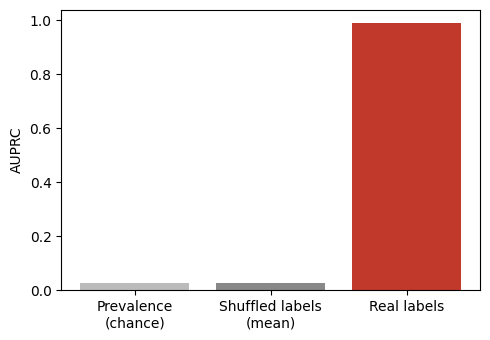

In [8]:
# 3c. positive controls: predict age and sex from the embeddings ONLY (no AF label, no age/sex features)
age = D["Age"].values.astype(float)
pred_age = np.zeros(len(age))
for tr, te in GroupKFold(5).split(E, age, groups):
    m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(0, 4, 9)))
    m.fit(E[tr], age[tr]); pred_age[te] = m.predict(E[te])
r2 = 1 - ((age - pred_age) ** 2).sum() / ((age - age.mean()) ** 2).sum()
mae = np.abs(age - pred_age).mean()
log("3", f"Age predicted from embeddings (MAE {mae:.1f} years): R^2", round(r2, 3), "PASS" if r2 >= 0.2 else "CHECK")

male = D["male"].values.astype(int)
folds_sex = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(E, male, groups))
auc_sex = roc_auc_score(male, oof(E, male, folds_sex))
log("3", "Sex predicted from embeddings: AUROC", round(auc_sex, 3), "PASS" if auc_sex >= 0.85 else "CHECK")

# figure: real vs shuffled
plt.figure(figsize=(5, 3.5))
plt.bar(["Prevalence\n(chance)", "Shuffled labels\n(mean)", "Real labels"], [prev, perm_mean, ap_real],
        color=["#bbb", "#888", "#c0392b"])
plt.ylabel("AUPRC"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "validation_fig_permutation.png"), dpi=200); plt.show()

## Summary

In [9]:
res = pd.DataFrame(summary)
res.to_csv(os.path.join(OUT_DIR, "validation_summary.csv"), index=False)
pd.set_option("display.max_colwidth", 110, "display.width", 200)
print(res.to_string(index=False))
n_check = int((res.Status == "CHECK").sum())
print(f"\n{(res.Status == 'PASS').sum()} PASS | {n_check} CHECK | {(res.Status == 'INFO').sum()} INFO")
print("No check flagged a problem." if n_check == 0 else "Investigate the CHECK rows before trusting the AUPRC.")

Test                                                                     Check            Value Status
   1                                           Embedding rows vs metadata rows   25770 vs 25770   PASS
   1                                      Record IDs unique in embeddings file             True   PASS
   1                                       Embedding IDs not found in metadata                0   PASS
   1                                            Metadata IDs with no embedding                0   PASS
   1                                                   Rows containing NaN/Inf                0   PASS
   1                                                      Zero-norm embeddings                0   PASS
   1                                         Exactly duplicated embedding rows              111  CHECK
   1                                                Constant (dead) dimensions                0   INFO
   1          Records whose stored window count != floor(N/2500) from met

## How to read the result

* **All PASS:** no evidence that the embeddings are misaligned, that train and test share patients or near-duplicate ECGs,
  or that the AF score arises from nothing. The high AUPRC is then most plausibly real signal.
* **A CHECK is a prompt to look, not proof of a leak.** The cutoffs (0.99 similarity, AUROC 0.6 / 0.9 / 0.85, R^2 0.2,
  0.01 AUPRC gap) are our own rules of thumb. Read the underlying numbers.
* **What these tests cannot rule out.** (1) Label noise: the AF labels are cardiologists' reads of the same ECG, so the score
  means "agrees with the reference read". (2) A shortcut shared by train and test, such as a device or site artifact tied to AF.
  (3) Whether the embeddings were computed correctly from the *raw signals*. Tests here only see the saved vectors.
  The most direct check for (3) is to re-run ECG-FM on a few dozen records and compare to the stored embeddings, which needs
  the raw signals and the model. An independent check for (1)-(2) is an RR-irregularity model computed from the raw signals.

In [10]:
# 1. Who are the duplicated embeddings?
h = pd.util.hash_pandas_object(pd.DataFrame(np.round(E_all, 4)), index=False).values
info = M.reset_index()[["rec", "Patient_ID", "Age", "male", "N", "af", "AHA_Code"]].assign(h=h)
info["grp_size"] = info.groupby("h")["rec"].transform("size")
dd = info[info.grp_size > 1]
g = dd.groupby("h").agg(size=("rec", "size"), n_patients=("Patient_ID", "nunique"),
                        n_af_values=("af", "nunique"), n_ages=("Age", "nunique"), n_lengths=("N", "nunique"))
print("duplicate groups:", len(g), "| records involved:", len(dd), "| redundant copies:", len(dd) - len(g))
print("group sizes:", g["size"].value_counts().to_dict())
print("groups spanning >1 patient:", int((g.n_patients > 1).sum()))
print("groups with conflicting AF labels:", int((g.n_af_values > 1).sum()))
print("groups with different recording lengths:", int((g.n_lengths > 1).sum()))
print("AF records among duplicated rows:", int(dd.af.sum()), "of", len(dd))
display(dd.sort_values("h").head(12))

# 2. The near-duplicate test records flagged in Test 2
for i in np.where(dupmask)[0]:
    j = nn[i]
    print(D.index[i], "->", D.index[j], "| sim", round(float(maxsim[i]), 4), "| patients", groups[i], groups[j],
          "| AF", y[i], y[j], "| N", D["N"].iloc[i], D["N"].iloc[j])

# 3. Does the score change if the redundant copies are dropped?
ok = (~pd.DataFrame(np.round(E_all, 4)).duplicated().values)[keep]
print("AUPRC all records:", round(average_precision_score(y, p_grouped), 4),
      "| without redundant copies:", round(average_precision_score(y[ok], p_grouped[ok]), 4))

duplicate groups: 111 | records involved: 222 | redundant copies: 111
group sizes: {2: 111}
groups spanning >1 patient: 0
groups with conflicting AF labels: 2
groups with different recording lengths: 0
AF records among duplicated rows: 8 of 222


,rec,Patient_ID,Age,male,N,af,AHA_Code,h,grp_size
12331,A12332,S10827,64,1,5000,0,106,324633811326173,2
11046,A11047,S10827,64,1,5000,0,106,324633811326173,2
316,A00317,S00317,57,0,5000,0,1,24437209193427188,2
22474,A22475,S00317,57,0,5000,0,1,24437209193427188,2
18357,A18358,S08767,61,1,5000,0,1,45920043931284294,2
8907,A08908,S08767,61,1,5000,0,1,45920043931284294,2
9783,A09784,S09610,72,1,5000,0,106;60+308;82,163879366468246823,2
13473,A13474,S09610,72,1,5000,0,106;60+308,163879366468246823,2
6671,A06672,S06593,27,1,5000,0,23,376345852833850582,2
9801,A09802,S06593,27,1,5000,0,23,376345852833850582,2


A02433 -> A06050 | sim 0.9941 | patients S02415 S05986 | AF 0 0 | N 5000 5000
A06050 -> A02433 | sim 0.9941 | patients S05986 S02415 | AF 0 0 | N 5000 5000
AUPRC all records: 0.9881 | without redundant copies: 0.988
